# Laboratorium 3 – sieć Hopfielda (część pierwsza)

## 1. Środowisko

In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Wzorce – cyfry 0–9

In [103]:
# Każda cyfra to 8 napisów po 8 znaków: '#' = piksel aktywny (+1), '.' = nieaktywny (-1)
cyfry_tekst = {
    0: [".######.",
        "##....##",
        "##....##",
        "##....##",
        "##....##",
        "##....##",
        "##....##",
        ".######."],
    1: ["...##...",
        "..###...",
        ".####...",
        "...##...",
        "...##...",
        "...##...",
        "...##...",
        ".######."],
    2: [".######.",
        "##....##",
        "......##",
        ".....##.",
        "...###..",
        "..##....",
        ".##.....",
        "########"],
    3: [".######.",
        "##....##",
        "......##",
        "..#####.",
        "......##",
        "......##",
        "##....##",
        ".######."],
    4: ["....##..",
        "...###..",
        "..####..",
        ".##.##..",
        "##..##..",
        "########",
        "....##..",
        "....##.."],
    5: ["########",
        "##......",
        "##......",
        "######..",
        "......##",
        "......##",
        "##....##",
        ".######."],
    6: ["..####..",
        ".##.....",
        "##......",
        "######..",
        "##...##.",
        "##...##.",
        "##...##.",
        ".#####.."],
    7: ["########",
        "......##",
        ".....##.",
        "....##..",
        "...##...",
        "..##....",
        "..##....",
        "..##...."],
    8: [".######.",
        "##....##",
        "##....##",
        ".######.",
        "##....##",
        "##....##",
        "##....##",
        ".######."],
    9: [".######.",
        "##....##",
        "##....##",
        ".#######",
        "......##",
        "......##",
        ".....##.",
        ".####..."],
}

def tekst_na_wektor(wiersze):
    """Zamienia 8 napisów na wektor 64 liczb: +1 lub -1."""
    wektor = []
    for wiersz in wiersze:
        for znak in wiersz:
            if znak == "#":
                wektor.append(1)
            else:
                wektor.append(-1)
    return np.array(wektor)

wzorce_cyfr = []
for cyfra in range(10):
    assert len(cyfry_tekst[cyfra]) == 8
    for wiersz in cyfry_tekst[cyfra]:
        assert len(wiersz) == 8
    wzorce_cyfr.append(tekst_na_wektor(cyfry_tekst[cyfra]))
wzorce_cyfr = np.array(wzorce_cyfr)     # tablica 10 x 64
print("Wzorce:", wzorce_cyfr.shape)

Wzorce: (10, 64)


In [104]:
def pokaz_obrazy(obrazy, tytuly, w_wierszu=10):
    """Rysuje obrazy 8x8 (czarny = +1, biały = -1)."""
    ile = len(obrazy)
    wierszy = (ile + w_wierszu - 1) // w_wierszu
    plt.figure(figsize=(1.4 * w_wierszu, 1.7 * wierszy))
    for i in range(ile):
        plt.subplot(wierszy, w_wierszu, i + 1)
        plt.imshow(obrazy[i].reshape(8, 8), cmap="gray_r", vmin=-1, vmax=1)
        plt.title(tytuly[i], fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

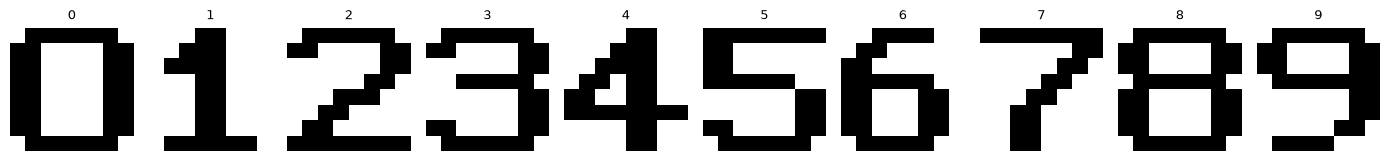

In [105]:
pokaz_obrazy(wzorce_cyfr, [str(i) for i in range(10)])

### Trzy warianty każdej cyfry

In [106]:
def przesun(wektor, w_prawo, w_dol):
    """Przesuwa obraz 8x8 o kilka pikseli. Puste miejsca wypełnia tłem (-1)."""
    obraz = wektor.reshape(8, 8)
    nowy = -np.ones((8, 8), dtype=int)
    for r in range(8):
        for k in range(8):
            r2 = r + w_dol
            k2 = k + w_prawo
            if 0 <= r2 < 8 and 0 <= k2 < 8:
                nowy[r2][k2] = obraz[r][k]
    return nowy.reshape(64)

warianty = []
for cyfra in range(10):
    w0 = wzorce_cyfr[cyfra]
    w1 = przesun(w0, -1, 0)
    w2 = przesun(w0, 0, 1)
    warianty.append([w0, w1, w2])

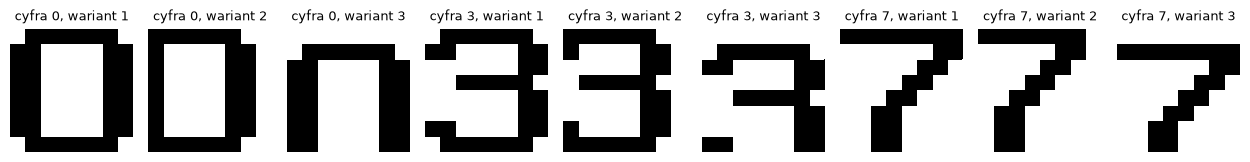

In [107]:
obrazy = []
tytuly = []
for cyfra in [0, 3, 7]:
    for w in range(3):
        obrazy.append(warianty[cyfra][w])
        tytuly.append("cyfra " + str(cyfra) + ", wariant " + str(w + 1))
pokaz_obrazy(obrazy, tytuly, w_wierszu=9)

## 3. Szum

In [108]:
def dodaj_szum(wzorzec, procent, rng):
    """Odwraca znak losowo wybranych pikseli. procent = ile % z 64 pikseli zepsuć."""
    ile = int(round(64 * procent / 100))
    numery = rng.choice(64, ile, replace=False)
    kopia = wzorzec.copy()
    for n in numery:
        kopia[n] = -kopia[n]
    return kopia

def zbuduj_zbior(ile_wariantow, ziarno=1):
    """ile_wariantow = 1 -> 10 wzorców, ile_wariantow = 3 -> 30 wzorców."""
    rng = np.random.RandomState(ziarno)
    wzorce = []
    etykiety = []
    for cyfra in range(10):
        for w in range(ile_wariantow):
            wzorce.append(warianty[cyfra][w])
            etykiety.append(cyfra)
    wzorce = np.array(wzorce)

    zbior = {"wzorce": wzorce, "etykiety": etykiety}
    for procent in [10, 20, 30]:
        kopie = []
        for wz in wzorce:
            kopie.append(dodaj_szum(wz, procent, rng))
        zbior[procent] = np.array(kopie)
    return zbior

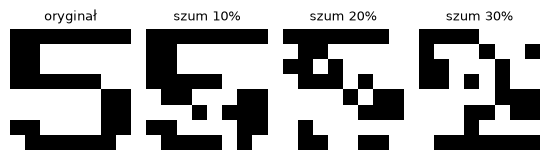

In [109]:
# przed i po dodaniu szumu dla cyfry 5
rng = np.random.RandomState(0)
obrazy = [wzorce_cyfr[5]]
tytuly = ["oryginał"]
for procent in [10, 20, 30]:
    obrazy.append(dodaj_szum(wzorce_cyfr[5], procent, rng))
    tytuly.append("szum " + str(procent) + "%")
pokaz_obrazy(obrazy, tytuly, w_wierszu=4)

In [110]:
# kontrola
rng = np.random.RandomState(0)
for procent in [10, 20, 30]:
    zaszumiony = dodaj_szum(wzorce_cyfr[5], procent, rng)
    zmienione = np.sum(zaszumiony != wzorce_cyfr[5])
    print(procent, "% szumu ->", zmienione, "zmienionych pikseli z 64")

10 % szumu -> 6 zmienionych pikseli z 64
20 % szumu -> 13 zmienionych pikseli z 64
30 % szumu -> 19 zmienionych pikseli z 64


## 4. Zbiory danych

In [111]:
zbior10 = zbuduj_zbior(ile_wariantow=1)
zbior30 = zbuduj_zbior(ile_wariantow=3)

for nazwa, zbior in [("mały (10)", zbior10), ("duży (30)", zbior30)]:
    print("Zbiór", nazwa)
    print("  wzorce:", len(zbior["wzorce"]))
    print("  kopie 10%:", len(zbior[10]), " kopie 20%:", len(zbior[20]), " kopie 30%:", len(zbior[30]))
    print("  razem obrazów:", len(zbior["wzorce"]) + len(zbior[10]) + len(zbior[20]) + len(zbior[30]))

Zbiór mały (10)
  wzorce: 10
  kopie 10%: 10  kopie 20%: 10  kopie 30%: 10
  razem obrazów: 40
Zbiór duży (30)
  wzorce: 30
  kopie 10%: 30  kopie 20%: 30  kopie 30%: 30
  razem obrazów: 120


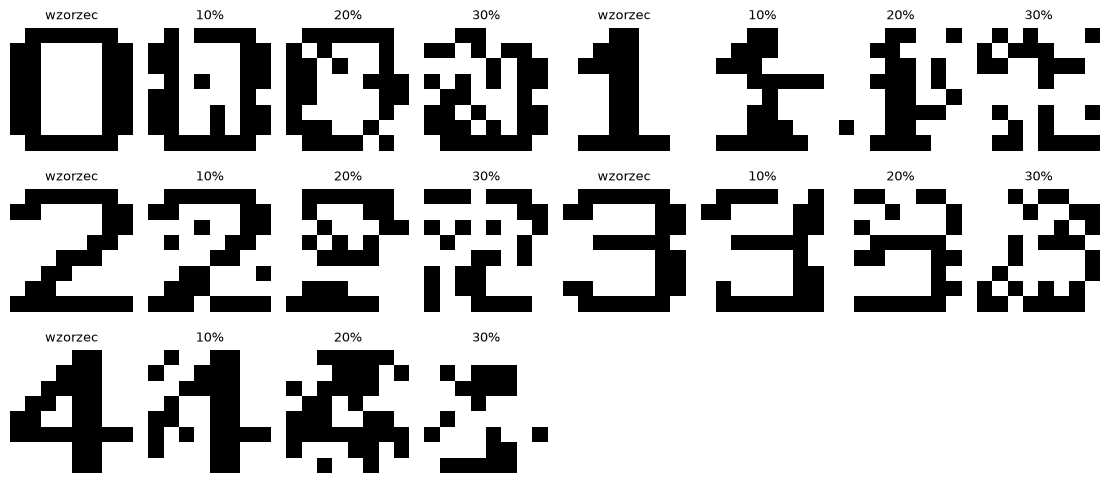

In [112]:
# podgląd
obrazy = []
tytuly = []
for i in range(5):
    obrazy.append(zbior10["wzorce"][i]);  tytuly.append("wzorzec")
    for procent in [10, 20, 30]:
        obrazy.append(zbior10[procent][i]); tytuly.append(str(procent) + "%")
pokaz_obrazy(obrazy, tytuly, w_wierszu=8)

## 5. Sieć Hopfielda

In [113]:
W_pusta = np.zeros((64, 64))
print("Rozmiar macierzy wag:", W_pusta.shape)

Rozmiar macierzy wag: (64, 64)


In [114]:
N = 64   # neurony = pikseli

def pole_lokalne(W, s, i):
    """h_i = suma po j z w_ij * s_j"""
    return np.dot(W[i], s)

def nowy_stan(h, stary):
    if h > 0:
        return 1
    elif h < 0:
        return -1
    else:
        return stary          # h == 0 neuron zostaje jak był

def aktualizuj_neuron(W, s, i):
    """Aktualizuje JEDEN neuron. Zwraca True, jeśli jego stan się zmienił."""
    h = pole_lokalne(W, s, i)
    nowy = nowy_stan(h, s[i])
    zmiana = (nowy != s[i])
    s[i] = nowy
    return zmiana

def aktualizuj_siec(W, s, rng):
    """Jeden przebieg: każdy neuron raz, w losowej kolejności (po jednym na iterację)."""
    liczba_zmian = 0
    for i in rng.permutation(N):
        if aktualizuj_neuron(W, s, i):
            liczba_zmian = liczba_zmian + 1
    return liczba_zmian

def odtworz(W, start, max_przebiegow=30, ziarno=0):
    """Uruchamia sieć, aż się ustabilizuje (przebieg bez żadnej zmiany)."""
    rng = np.random.RandomState(ziarno)
    s = start.copy()
    for przebieg in range(max_przebiegow):
        zmiany = aktualizuj_siec(W, s, rng)
        if zmiany == 0:
            break
    return s

In [115]:
W_test = np.zeros((64, 64))
W_test[0][1] = 1.0      # neuron 0 słucha neuronu 1
s_test = -np.ones(64)
s_test[1] = 1           # neuron 1 jest aktywny

print("Pole lokalne neuronu 0:", pole_lokalne(W_test, s_test, 0))
print("Stan neuronu 0 przed:", s_test[0])
aktualizuj_neuron(W_test, s_test, 0)
print("Stan neuronu 0 po:   ", s_test[0])

Pole lokalne neuronu 0: 1.0
Stan neuronu 0 przed: -1.0
Stan neuronu 0 po:    1.0


## 6. Uczenie – reguła Hebba

In [116]:
def ucz_hebb(wzorce):
    """Reguła Hebba: W = (1/N) * suma po wzorcach z x * x^T, przekątna = 0."""
    W = np.zeros((N, N))
    for x in wzorce:
        W = W + np.outer(x, x)
    W = W / N
    for i in range(N):
        W[i][i] = 0
    return W

In [117]:
W10 = ucz_hebb(zbior10["wzorce"])
W30 = ucz_hebb(zbior30["wzorce"])
print("Wagi dla 10 wzorców:", W10.shape)
print("Wagi dla 30 wzorców:", W30.shape)

Wagi dla 10 wzorców: (64, 64)
Wagi dla 30 wzorców: (64, 64)


## 7. Sprawdzenia

### 7.1 Symetria i zera na przekątnej

In [118]:
def sprawdz_odtwarzanie(W, wzorce, obrazy):
    """Dla każdego obrazu uruchamia sieć i porównuje wynik z właściwym wzorcem.
    Zwraca: (ile % odtworzonych dokładnie, średnia % zgodnych pikseli)."""
    dokladnie = 0
    suma_zgodnych = 0
    for i in range(len(obrazy)):
        wynik = odtworz(W, obrazy[i], ziarno=i)
        if np.array_equal(wynik, wzorce[i]):
            dokladnie = dokladnie + 1
        suma_zgodnych = suma_zgodnych + np.mean(wynik == wzorce[i])
    return 100 * dokladnie / len(obrazy), 100 * suma_zgodnych / len(obrazy)

def sprawdz_wagi(W, nazwa=""):
    symetryczna = np.allclose(W, W.T)
    zera = np.allclose(np.diag(W), 0)
    print(nazwa, "| symetryczna:", symetryczna, "| zera na przekątnej:", zera)

In [119]:
sprawdz_wagi(W10, "Hebb, 10 wzorców")
sprawdz_wagi(W30, "Hebb, 30 wzorców")

Hebb, 10 wzorców | symetryczna: True | zera na przekątnej: True
Hebb, 30 wzorców | symetryczna: True | zera na przekątnej: True


### 7.2 Czy sieć odtwarza niezaszumiony wzorzec?

In [120]:
for nazwa, W, zbior in [("10 wzorców", W10, zbior10), ("30 wzorców", W30, zbior30)]:
    dokladnie, pikseli = sprawdz_odtwarzanie(W, zbior["wzorce"], zbior["wzorce"])
    print("Hebb,", nazwa, "-> wzorców bez zmian:", round(dokladnie, 1), "% | zgodnych pikseli:", round(pikseli, 1), "%")

Hebb, 10 wzorców -> wzorców bez zmian: 10.0 % | zgodnych pikseli: 80.6 %
Hebb, 30 wzorców -> wzorców bez zmian: 0.0 % | zgodnych pikseli: 75.7 %


### 7.3 Czy sieć naprawia zaszumione obrazy?

In [121]:
wyniki = []
for nazwa, W, zbior in [("10 wzorców", W10, zbior10), ("30 wzorców", W30, zbior30)]:
    for procent in [10, 20, 30]:
        dokladnie, pikseli = sprawdz_odtwarzanie(W, zbior["wzorce"], zbior[procent])
        wyniki.append([nazwa, str(procent) + "%", round(dokladnie, 1), round(pikseli, 1)])

tabela = pd.DataFrame(wyniki, columns=["zbiór", "szum", "odtworzone dokładnie %", "zgodne piksele %"])
tabela

,zbiór,szum,odtworzone dokładnie %,zgodne piksele %
0,10 wzorców,10%,0.0,75.9
1,10 wzorców,20%,0.0,75.9
2,10 wzorców,30%,0.0,75.9
3,30 wzorców,10%,0.0,75.9
4,30 wzorców,20%,0.0,75.1
5,30 wzorców,30%,0.0,68.1


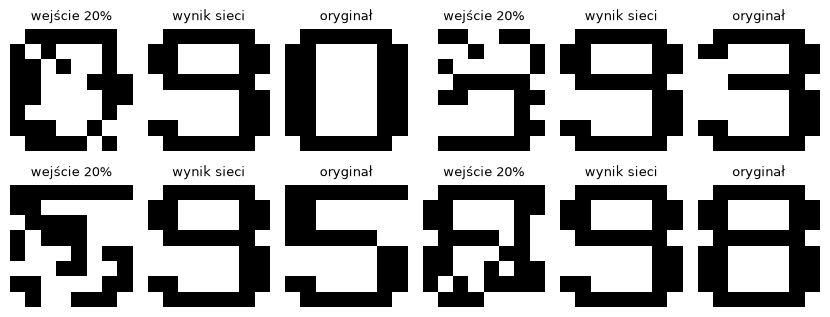

In [122]:
# przykłady
obrazy = []
tytuly = []
for i in [0, 3, 5, 8]:
    wejscie = zbior10[20][i]
    wynik = odtworz(W10, wejscie, ziarno=i)
    obrazy.append(wejscie);                tytuly.append("wejście 20%")
    obrazy.append(wynik);                  tytuly.append("wynik sieci")
    obrazy.append(zbior10["wzorce"][i]);   tytuly.append("oryginał")
pokaz_obrazy(obrazy, tytuly, w_wierszu=6)

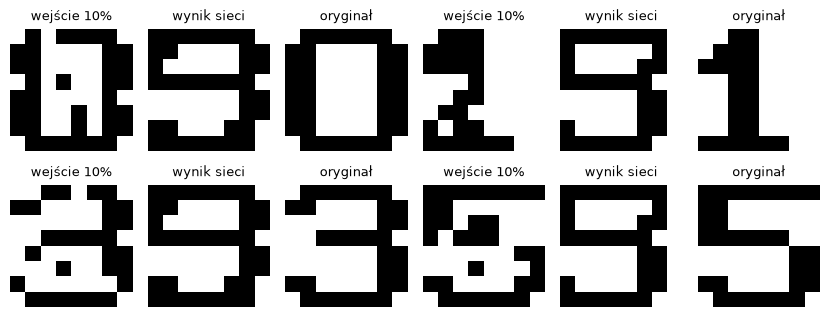

In [123]:
# to samo dla dużego zbioru
obrazy = []
tytuly = []
for i in [0, 4, 9, 15]:
    wejscie = zbior30[10][i]
    wynik = odtworz(W30, wejscie, ziarno=i)
    obrazy.append(wejscie);                tytuly.append("wejście 10%")
    obrazy.append(wynik);                  tytuly.append("wynik sieci")
    obrazy.append(zbior30["wzorce"][i]);   tytuly.append("oryginał")
pokaz_obrazy(obrazy, tytuly, w_wierszu=6)

## 8. Wnioski

- Czy macierz wag jest symetryczna i czy ma zera na przekątnej?
- Tak, obie rzeczy się zgadzają (np.allclose(W, W.T) i zerowanie przekątnej) co wynika z samej konstrukcji W z reguły Hebba.
- Czy sieć zachowuje czyste wzorce? Czy jest różnica między zbiorem 10 a 30 wzorców?
- Nie przy 10 wzorcach stabilny był tylko 1 z 10, a przy 30 żaden. Wzorce są do siebie za bardzo podobne i przekraczają pojemność sieci więc nie są stabilnymi atraktorami.
- Jak zmienia się skuteczność odtwarzania wraz ze wzrostem szumu?
- Dokładne odtworzenie to 0% już przy 10% szumu a zgodność pikseli spada z ok. 76% do 68%. Szum prawie nie ma znaczenia bo sieć i tak nie odtwarza nawet czystych wzorców.
- Dlaczego przy 30 wzorcach jest gorzej? (podpowiedź: pojemność pamięci sieci Hopfielda z regułą Hebba to ok. 0,14·N wzorców, czyli ok. 9 dla N = 64, a wzorce muszą być do siebie niepodobne)
- Pojemność Hebba to ok. 0,14·N czyli 9 wzorców więc 30 wzorców znacznie ją przekracza a do tego wzorce są skorelowane co dodatkowo psuje wagi.
- Co się stało z wzorcami, które sieć odtworzyła źle: skończyły jako inna cyfra, czy jako „śmieć”?
- Skończyły jako „śmieć”: 10 zaszumionych obrazów trafiło tylko w 2 różne stany końcowe które przypominają pojedynczą cyfrę (najczęściej 3, zgodność 61 z 64 pikseli) z kilkoma błędnymi pikselami. To stany fałszywe a nie poprawnie odtworzone wzorce.